In [ ]:
!pip install ultralytics roboflow opencv-python-headless
!pip install matplotlib numpy scikit-image scikit-learn albumentations

In [ ]:
import os
import cv2
import yaml
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from skimage.metrics import peak_signal_noise_ratio as psnr_metric
from skimage.metrics import structural_similarity as ssim_metric
from ultralytics import YOLO

# Configurações globais
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

TARGET_SIZE = (640, 640)   # Tamanho padrão YOLOv8
CONF_THRESH  = 0.40        # Limiar de confiança para inferência
IOU_THRESH   = 0.50        # IoU para métricas de avaliação
EPOCHS       = 50
BATCH        = 16

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
def download_roboflow_dataset():
    """
    Faz o download do dataset anotado no Roboflow no formato YOLOv8.

    Parâmetros:
        api_key   : Sua chave de API do Roboflow (Settings > API Keys)
        workspace : Nome do workspace (aparece na URL do Roboflow)
        project   : Nome do projeto
        version   : Versão do dataset a ser baixada (padrão: 1)

    Retorna:
        Caminho local do dataset baixado
    """
    from roboflow import Roboflow

    from google.colab import userdata
    rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))  # chave guardada nos Secrets do Colab
    project = rf.workspace("thiagos-workspace-z6ywv").project("deteccao-de-pessoas-6ftr8")
    dataset = project.version(2).download("yolov8")

    print(f"Dataset baixado em: {dataset.location}")
    return dataset.location

DATASET_PATH = download_roboflow_dataset()
#DATASET_PATH = "./dataset"     # Ou aponte para onde você extraiu manualmente
YAML_PATH    = os.path.join(DATASET_PATH, "data.yaml")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Detecçao-de-pessoas-2 in yolov8:: 100%|██████████| 211/211 [00:00<00:00, 726.44it/s]


Dataset baixado em: /content/Detecçao-de-pessoas-2


SUMÁRIO DO DATASET
Split      |  Imagens |  Pessoas |  Média/img
------------------------------------------------------------
train      |       57 |      535 |       9.39
valid      |       26 |      211 |       8.12
test       |       20 |      213 |      10.65


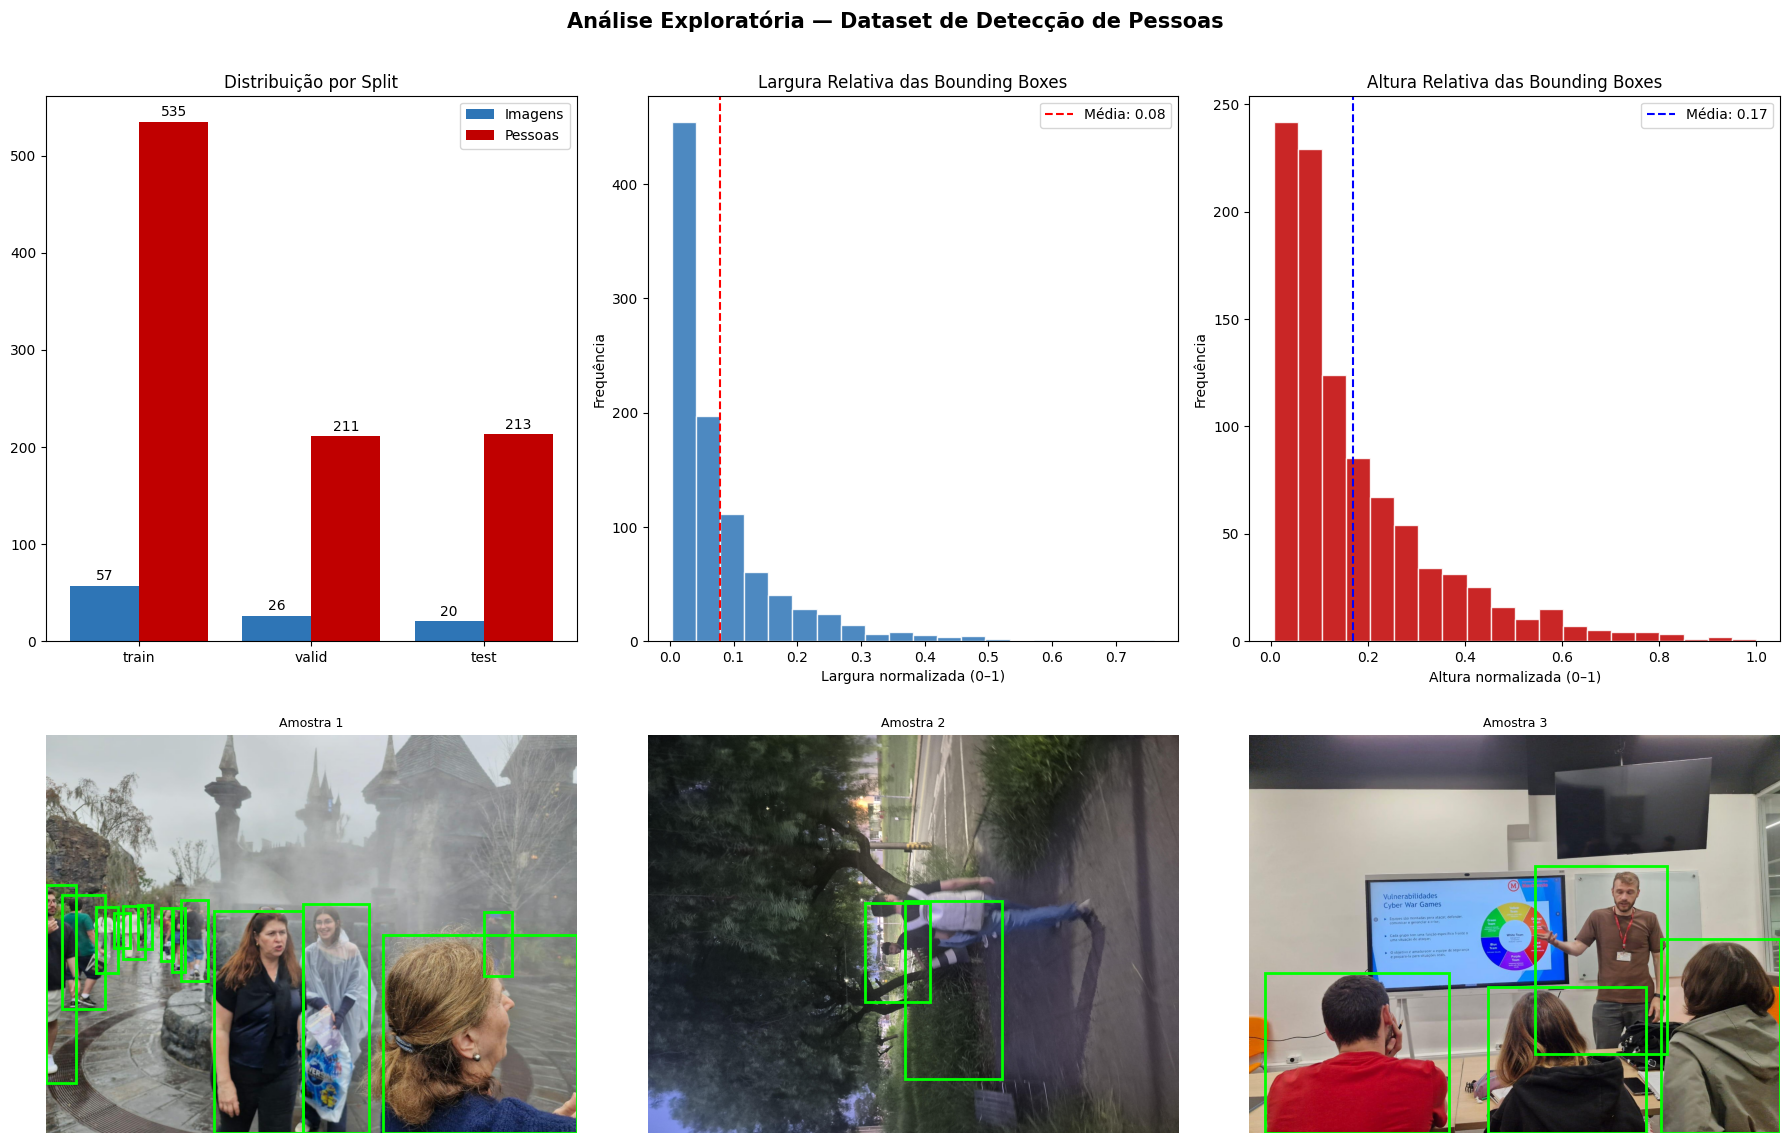

Gráfico salvo em: eda_dataset.png


In [ ]:
#download do dataset e EDA
def load_dataset_stats(dataset_path: str) -> dict:
    """
    Carrega estatísticas do dataset: contagem de imagens, instâncias,
    distribuição de tamanhos de bounding boxes por split.
    """
    splits = ["train", "valid", "test"]
    stats  = {}

    for split in splits:
        img_dir = Path(dataset_path) / split / "images"
        lbl_dir = Path(dataset_path) / split / "labels"

        if not img_dir.exists():
            continue

        images      = sorted(list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png")))
        n_instances = []
        widths, heights = [], []

        for img_path in images:
            lbl_path = lbl_dir / (img_path.stem + ".txt")
            if lbl_path.exists():
                with open(lbl_path) as f:
                    lines = [l.strip() for l in f if l.strip()]
                n_instances.append(len(lines))
                for line in lines:
                    parts = line.split()
                    if len(parts) == 5:
                        widths.append(float(parts[3]))
                        heights.append(float(parts[4]))
            else:
                n_instances.append(0)

        stats[split] = {
            "n_images"     : len(images),
            "n_instances"  : sum(n_instances),
            "avg_per_image": float(np.mean(n_instances)) if n_instances else 0.0,
            "max_per_image": max(n_instances) if n_instances else 0,
            "bbox_widths"  : widths,
            "bbox_heights" : heights,
        }

    return stats


def print_dataset_stats(stats: dict):
    """Exibe sumário do dataset no terminal."""
    print("=" * 60)
    print("SUMÁRIO DO DATASET")
    print("=" * 60)
    print(f"{'Split':<10} | {'Imagens':>8} | {'Pessoas':>8} | {'Média/img':>10}")
    print("-" * 60)
    for split, s in stats.items():
        print(f"{split:<10} | {s['n_images']:>8} | {s['n_instances']:>8} | {s['avg_per_image']:>10.2f}")
    print("=" * 60)


def plot_eda(stats: dict, dataset_path: str, n_samples: int = 6):
    """
    Plota:
      - Contagem de imagens e instâncias por split (barras)
      - Distribuição do tamanho relativo das bounding boxes
      - Amostras aleatórias do split de treinamento com anotações
    """
    fig = plt.figure(figsize=(18, 12))
    fig.suptitle("Análise Exploratória — Dataset de Detecção de Pessoas",
                 fontsize=15, fontweight="bold", y=1.01)

    # ── Subplot 1: Contagem por split ──────────────────────────────────────
    ax1 = fig.add_subplot(2, 3, 1)
    splits     = list(stats.keys())
    n_images   = [stats[s]["n_images"]    for s in splits]
    n_instances= [stats[s]["n_instances"] for s in splits]
    x = np.arange(len(splits))
    bars1 = ax1.bar(x - 0.2, n_images,    0.4, label="Imagens",  color="#2E75B6")
    bars2 = ax1.bar(x + 0.2, n_instances, 0.4, label="Pessoas",  color="#C00000")
    ax1.set_xticks(x); ax1.set_xticklabels(splits)
    ax1.set_title("Distribuição por Split"); ax1.legend()
    ax1.bar_label(bars1, padding=2); ax1.bar_label(bars2, padding=2)

    # ── Subplot 2: Histograma de largura das bboxes ─────────────────────────
    ax2 = fig.add_subplot(2, 3, 2)
    all_widths = []
    for s in stats.values():
        all_widths.extend(s["bbox_widths"])
    ax2.hist(all_widths, bins=20, color="#2E75B6", edgecolor="white", alpha=0.85)
    ax2.set_title("Largura Relativa das Bounding Boxes")
    ax2.set_xlabel("Largura normalizada (0–1)")
    ax2.set_ylabel("Frequência")
    ax2.axvline(np.mean(all_widths), color="red", linestyle="--",
                label=f"Média: {np.mean(all_widths):.2f}")
    ax2.legend()

    # ── Subplot 3: Histograma de altura das bboxes ──────────────────────────
    ax3 = fig.add_subplot(2, 3, 3)
    all_heights = []
    for s in stats.values():
        all_heights.extend(s["bbox_heights"])
    ax3.hist(all_heights, bins=20, color="#C00000", edgecolor="white", alpha=0.85)
    ax3.set_title("Altura Relativa das Bounding Boxes")
    ax3.set_xlabel("Altura normalizada (0–1)")
    ax3.set_ylabel("Frequência")
    ax3.axvline(np.mean(all_heights), color="blue", linestyle="--",
                label=f"Média: {np.mean(all_heights):.2f}")
    ax3.legend()

    # ── Subplots 4-6: Amostras com anotações ───────────────────────────────
    train_img_dir = Path(dataset_path) / "train" / "images"
    train_lbl_dir = Path(dataset_path) / "train" / "labels"
    train_imgs    = sorted(list(train_img_dir.glob("*.jpg")) + list(train_img_dir.glob("*.png")))
    samples       = random.sample(train_imgs, min(n_samples, len(train_imgs)))

    for i, img_path in enumerate(samples[:3]):
        ax = fig.add_subplot(2, 3, 4 + i)
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax.imshow(img)

        lbl_path = train_lbl_dir / (img_path.stem + ".txt")
        if lbl_path.exists():
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) == 5:
                        _, xc, yc, bw, bh = map(float, parts)
                        x1 = (xc - bw / 2) * w
                        y1 = (yc - bh / 2) * h
                        rect = patches.Rectangle(
                            (x1, y1), bw * w, bh * h,
                            linewidth=2, edgecolor="lime", facecolor="none"
                        )
                        ax.add_patch(rect)

        ax.set_title(f"Amostra {i+1}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig("eda_dataset.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Gráfico salvo em: eda_dataset.png")


# Executar EDA
stats = load_dataset_stats(DATASET_PATH)
print_dataset_stats(stats)
plot_eda(stats, DATASET_PATH)


Método       |  PSNR (dB) |     SSIM
--------------------------------------
Gaussiano    |      28.30 |   0.7311
Bilateral    |      31.16 |   0.8095
NLM          |      29.43 |   0.7421


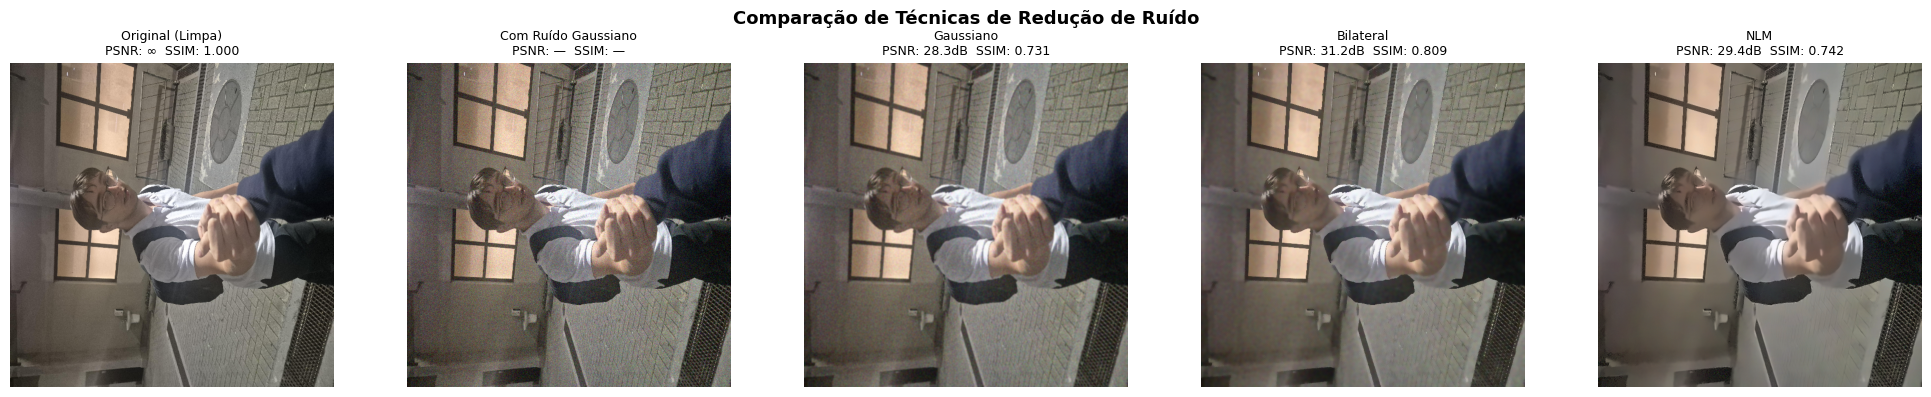

Gráfico salvo em: comparacao_denoising.png


In [ ]:
#Pre-processamento analise
def add_gaussian_noise(img: np.ndarray, sigma: float = 15.0) -> np.ndarray:
    """Adiciona ruído gaussiano artificial para benchmark de denoising."""
    noise  = np.random.normal(0, sigma, img.shape).astype(np.float32)
    return np.clip(img.astype(np.float32) + noise, 0, 255).astype(np.uint8)


def apply_denoising(img_noisy: np.ndarray) -> dict:
    """
    Aplica três técnicas de redução de ruído.

    Retorna dicionário com as imagens filtradas por cada método.
    """
    return {
        "Gaussiano" : cv2.GaussianBlur(img_noisy, (5, 5), 1.0),
        "Bilateral" : cv2.bilateralFilter(img_noisy, d=9, sigmaColor=75, sigmaSpace=75),
        "NLM"       : cv2.fastNlMeansDenoisingColored(img_noisy, None, 10, 10, 7, 21),
    }


def evaluate_denoising(original: np.ndarray, results: dict) -> None:
    """Imprime PSNR e SSIM para cada método."""
    print(f"\n{'Método':<12} | {'PSNR (dB)':>10} | {'SSIM':>8}")
    print("-" * 38)
    for name, img in results.items():
        p = psnr_metric(original, img, data_range=255)
        s = ssim_metric(original, img, channel_axis=2, data_range=255)
        print(f"{name:<12} | {p:>10.2f} | {s:>8.4f}")


def plot_denoising_comparison(original: np.ndarray, img_noisy: np.ndarray,
                               results: dict, save_path: str = "comparacao_denoising.png"):
    """Plota a comparação visual entre as técnicas de denoising."""
    titles = ["Original (Limpa)", "Com Ruído Gaussiano"] + list(results.keys())
    images = [original, img_noisy] + list(results.values())

    fig, axes = plt.subplots(1, len(images), figsize=(4 * len(images), 4))
    fig.suptitle("Comparação de Técnicas de Redução de Ruído", fontsize=13, fontweight="bold")

    for ax, title, img in zip(axes, titles, images):
        ax.imshow(img)
        p = psnr_metric(original, img, data_range=255) if "Original" not in title else float("inf")
        s = ssim_metric(original, img, channel_axis=2, data_range=255) if "Original" not in title else 1.0
        subtitle = f"PSNR: ∞  SSIM: 1.000" if title == "Original (Limpa)" \
                   else (f"PSNR: —  SSIM: —" if "Ruído" in title
                         else f"PSNR: {p:.1f}dB  SSIM: {s:.3f}")
        ax.set_title(f"{title}\n{subtitle}", fontsize=9)
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Gráfico salvo em: {save_path}")


def run_denoising_benchmark(dataset_path: str, n_samples: int = 5):
    """
    Executa o benchmark de denoising em amostras aleatórias do conjunto de treino.
    """
    img_dir = Path(dataset_path) / "train" / "images"
    imgs    = sorted(list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png")))
    if not imgs:
        print("Nenhuma imagem encontrada. Verifique DATASET_PATH.")
        return

    sample_path = random.choice(imgs)
    img_bgr     = cv2.imread(str(sample_path))
    img_rgb     = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_rgb     = cv2.resize(img_rgb, TARGET_SIZE, interpolation=cv2.INTER_CUBIC)

    img_noisy   = add_gaussian_noise(img_rgb, sigma=15.0)
    results     = apply_denoising(img_noisy)

    evaluate_denoising(img_rgb, results)
    plot_denoising_comparison(img_rgb, img_noisy, results)


run_denoising_benchmark(DATASET_PATH)

In [ ]:
#Pre-processamento na base
def preprocess_image(img_path: str,
                     target_size: tuple = TARGET_SIZE,
                     apply_bilateral: bool = True) -> np.ndarray:
    """
    Pipeline completo de pré-processamento para uma imagem:
      1. Leitura e conversão BGR → RGB
      2. Redimensionamento para target_size com interpolação adequada
      3. Filtragem bilateral (denoising com preservação de bordas)
      4. Normalização para [0, 1]

    Retorna: array float32 normalizado (H × W × 3)
    """
    img = cv2.imread(img_path)
    if img is None:
        raise FileNotFoundError(f"Não foi possível abrir: {img_path}")

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    h, w = img.shape[:2]
    interp = cv2.INTER_AREA if (w > target_size[0] or h > target_size[1]) else cv2.INTER_CUBIC
    img    = cv2.resize(img, target_size, interpolation=interp)

    if apply_bilateral:
        img = cv2.bilateralFilter(img, d=9, sigmaColor=75, sigmaSpace=75)

    img_norm = img.astype(np.float32) / 255.0
    return img_norm


def compute_dataset_statistics(dataset_path: str, split: str = "train") -> dict:
    """
    Calcula média e desvio-padrão por canal RGB no split de treinamento.
    Útil para futura normalização no estilo ImageNet.
    """
    img_dir = Path(dataset_path) / split / "images"
    images  = sorted(list(img_dir.glob("*.jpg")) + list(img_dir.glob("*.png")))

    means, stds = [], []
    for img_path in images[:100]:  # Usar até 100 imagens para eficiência
        img = preprocess_image(str(img_path))
        means.append(img.mean(axis=(0, 1)))
        stds.append(img.std(axis=(0, 1)))

    mean_rgb = np.mean(means, axis=0)
    std_rgb  = np.mean(stds,  axis=0)

    print(f"\nEstatísticas do Dataset (split={split}, n={len(images)}):")
    print(f"  Média por canal: R={mean_rgb[0]:.4f}  G={mean_rgb[1]:.4f}  B={mean_rgb[2]:.4f}")
    print(f"  Desvio-padrão:   R={std_rgb[0]:.4f}   G={std_rgb[1]:.4f}   B={std_rgb[2]:.4f}")

    return {"mean": mean_rgb.tolist(), "std": std_rgb.tolist()}


dataset_stats = compute_dataset_statistics(DATASET_PATH)



Estatísticas do Dataset (split=train, n=57):
  Média por canal: R=0.4568  G=0.4320  B=0.4201
  Desvio-padrão:   R=0.2110   G=0.2069   B=0.2102


In [ ]:
#Treinamento do modelo
def train_yolov8(yaml_path: str,
                 model_size: str = "n",
                 epochs: int = EPOCHS,
                 batch: int = BATCH,
                 imgsz: int = TARGET_SIZE[0]) -> str:
    """
    Treina um modelo YOLOv8 com transfer learning a partir de pesos COCO.

    Parâmetros:
        yaml_path  : Caminho para o data.yaml do Roboflow
        model_size : 'n' (nano), 's' (small), 'm' (medium), 'l' (large)
        epochs     : Número de épocas de treinamento
        batch      : Tamanho do batch (reduza para 8 se faltar memória GPU)
        imgsz      : Resolução de entrada (640 padrão YOLOv8)

    Retorna:
        Caminho para o melhor modelo salvo (best.pt)
    """
    import torch
    model = YOLO(f"yolov8{model_size}.pt")

    results = model.train(
        data       = yaml_path,
        epochs     = epochs,
        imgsz      = imgsz,
        batch      = batch,
        lr0        = 0.01,
        lrf        = 0.01,
        momentum   = 0.937,
        weight_decay = 0.0005,
        optimizer  = "SGD",
        augment    = True,      # Mosaic, MixUp, flip, jitter de cor
        patience   = 10,        # Early stopping se val/loss não melhorar
        project    = "runs/detect",
        name       = "person_detector",
        device     = 0 if torch.cuda.is_available() else "cpu",  # auto GPU/CPU
        save       = True,
        exist_ok   = True,
        verbose    = True,
    )

    best_model_path = str(results.save_dir / "weights" / "best.pt")
    print(f"\n✓ Treinamento concluído! Melhor modelo: {best_model_path}")
    return best_model_path


# Descomentar para treinar:
BEST_MODEL_PATH = train_yolov8(YAML_PATH, model_size="n", epochs=50)
#BEST_MODEL_PATH = "runs/detect/person_detector/weights/best.pt"


Ultralytics 8.4.54 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=True, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Detecçao-de-pessoas-2/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=person_detector, nbs=64, nms=False, opset=None, optimize=False, optimizer=SGD, overlap_mask=T

Ultralytics 8.4.54 🚀 Python-3.12.13 torch-2.10.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 662.8±66.9 MB/s, size: 889.0 KB)
val: Scanning /content/Detecçao-de-pessoas-2/test/labels... 20 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20 1.6Kit/s 0.0s
val: New cache created: /content/Detecçao-de-pessoas-2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 3.1s/it 6.1s
                   all         20        213      0.893      0.117      0.112     0.0751
Speed: 1.7ms preprocess, 258.7ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /content/runs/detect/val

MÉTRICAS DE AVALIAÇÃO — CONJUNTO DE TESTE
  mAP50       : 0.1121
  mAP50-95    : 0.0751
  Precision   : 0.8929
  Recall      : 0.1174
  F1          : 0.2075
results.csv encontrado em: runs/detect/runs/det

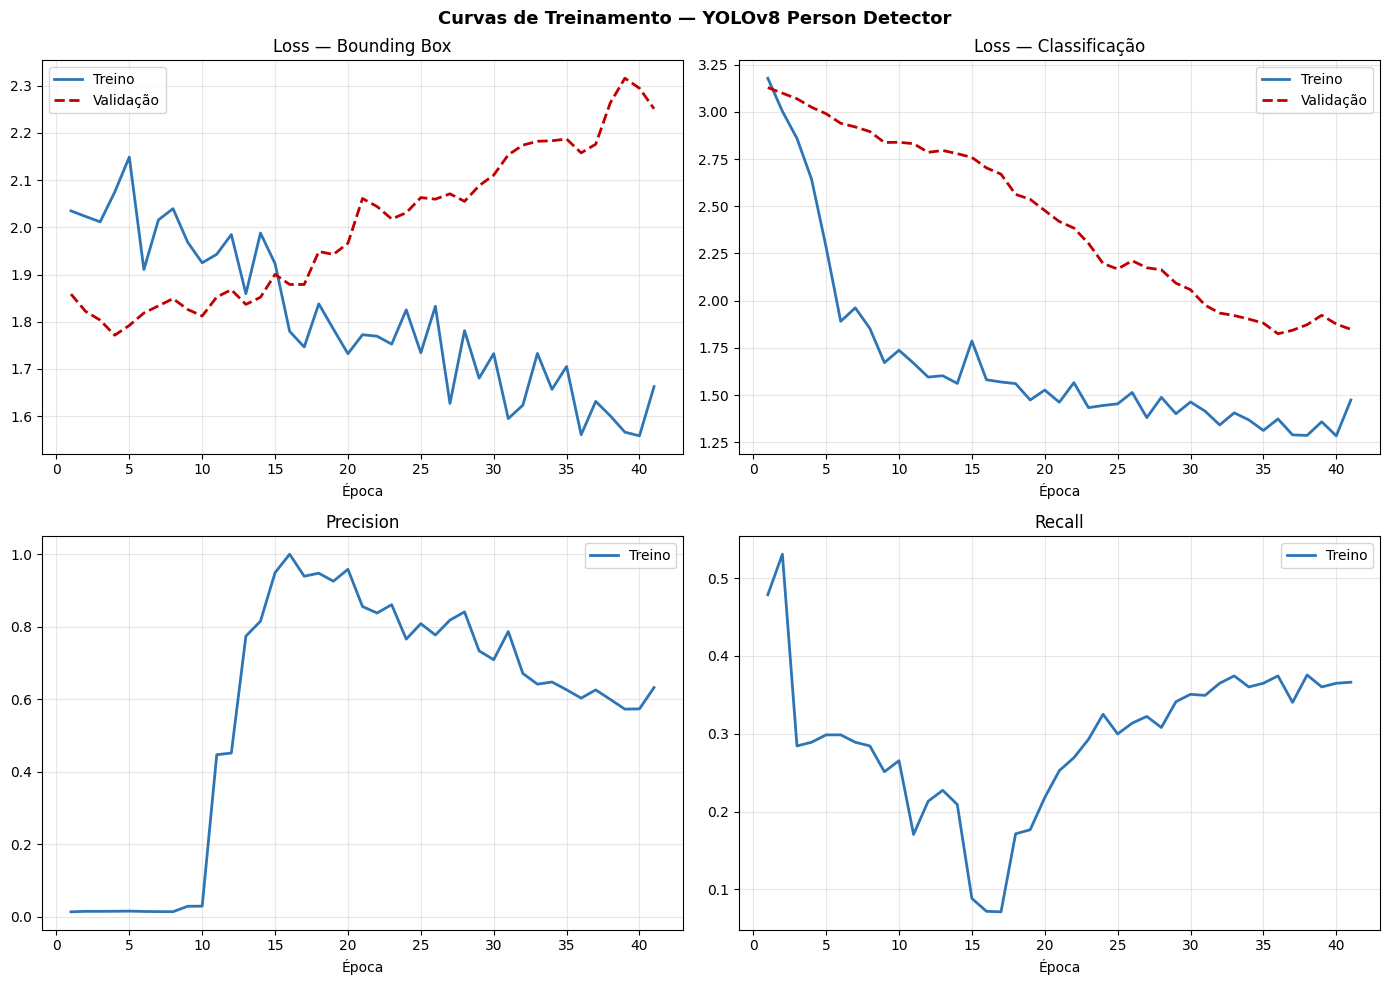

Curvas salvas em: curvas_treinamento.png


In [ ]:
#Avaliação do modelo
def evaluate_model(model_path: str, yaml_path: str) -> dict:
    """
    Avalia o modelo no conjunto de teste e retorna as métricas principais.

    Métricas retornadas:
        mAP@50     : mean Average Precision com IoU=0.50
        mAP@50-95  : mAP médio entre IoU=0.50 e IoU=0.95 (mais rigorosa)
        Precision  : TP / (TP + FP)
        Recall     : TP / (TP + FN)
    """
    model = YOLO(model_path)

    metrics = model.val(
        data   = yaml_path,
        split  = "test",
        imgsz  = TARGET_SIZE[0],
        conf   = CONF_THRESH,
        iou    = IOU_THRESH,
        verbose= True,
    )

    result = {
        "mAP50"    : metrics.box.map50,
        "mAP50-95" : metrics.box.map,
        "Precision": metrics.box.mp,
        "Recall"   : metrics.box.mr,
    }
    result["F1"] = (2 * result["Precision"] * result["Recall"] /
                    (result["Precision"] + result["Recall"] + 1e-9))

    print("\n" + "=" * 45)
    print("MÉTRICAS DE AVALIAÇÃO — CONJUNTO DE TESTE")
    print("=" * 45)
    for k, v in result.items():
        print(f"  {k:<12}: {v:.4f}")
    print("=" * 45)

    return result


def find_results_csv(base_dir: str = "runs/detect") -> Path | None:
    """
    Procura automaticamente o arquivo results.csv mais recente dentro de
    runs/detect/, independente do nome da subpasta gerada pelo YOLOv8.
    """
    base = Path(base_dir)
    if not base.exists():
        return None

    # Busca recursiva por qualquer results.csv dentro de runs/detect/
    candidates = sorted(base.rglob("results.csv"),
                        key=lambda p: p.stat().st_mtime, reverse=True)

    if candidates:
        print(f"results.csv encontrado em: {candidates[0]}")
        return candidates[0]

    # Fallback: listar o que existe para ajudar o diagnóstico
    print(f"Nenhum results.csv encontrado em '{base_dir}'.")
    print("Pastas disponíveis em runs/detect/:")
    for p in base.iterdir():
        print(f"  {p}")
        for f in p.iterdir():
            print(f"    {f.name}")
    return None


def plot_training_curves(run_dir: str = "runs/detect"):
    """
    Plota as curvas de loss e métricas salvas automaticamente pelo YOLOv8.
    Encontra o results.csv automaticamente dentro de runs/detect/.
    """
    import csv

    results_csv = find_results_csv(run_dir)
    if results_csv is None:
        return

    rows = []
    with open(results_csv) as f:
        reader = csv.DictReader(f)
        for row in reader:
            try:
                rows.append({k.strip(): float(v.strip()) for k, v in row.items()
                             if v.strip() not in ("", "nan", "inf")})
            except ValueError:
                continue

    if not rows:
        print("Nenhum dado de treinamento encontrado no CSV.")
        return

    print(f"Colunas disponíveis: {list(rows[0].keys())}")
    epochs = list(range(1, len(rows) + 1))

    # Pares de métricas a plotar (train_key, val_key, título)
    # Aceita tanto o formato antigo quanto o novo do YOLOv8
    metrics_to_plot = [
        ("train/box_loss",       "val/box_loss",       "Loss — Bounding Box"),
        ("train/cls_loss",       "val/cls_loss",       "Loss — Classificação"),
        ("metrics/precision(B)", None,                 "Precision"),
        ("metrics/recall(B)",    None,                 "Recall"),
    ]

    # Filtrar só os pares que existem no CSV
    valid_metrics = [
        (tk, vk, title) for tk, vk, title in metrics_to_plot
        if tk in rows[0] or (vk and vk in rows[0])
    ]

    if not valid_metrics:
        print("Nenhuma métrica conhecida encontrada. Colunas disponíveis:")
        for k in rows[0]:
            print(f"  {k}")
        return

    ncols = min(2, len(valid_metrics))
    nrows = (len(valid_metrics) + 1) // 2
    fig, axes = plt.subplots(nrows, ncols, figsize=(7 * ncols, 5 * nrows))
    axes = np.array(axes).flatten()

    fig.suptitle("Curvas de Treinamento — YOLOv8 Person Detector",
                 fontsize=13, fontweight="bold")

    for ax, (train_key, val_key, title) in zip(axes, valid_metrics):
        if train_key in rows[0]:
            ax.plot(epochs, [r[train_key] for r in rows],
                    label="Treino", color="#2E75B6", linewidth=2)
        if val_key and val_key in rows[0]:
            ax.plot(epochs, [r[val_key] for r in rows],
                    label="Validação", color="#C00000", linewidth=2, linestyle="--")
        ax.set_title(title)
        ax.set_xlabel("Época")
        ax.legend()
        ax.grid(True, alpha=0.3)

    # Ocultar eixos extras não usados
    for ax in axes[len(valid_metrics):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.savefig("curvas_treinamento.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Curvas salvas em: curvas_treinamento.png")


eval_results = evaluate_model(BEST_MODEL_PATH, YAML_PATH)
plot_training_curves()

In [ ]:
#Uso em imagens
def detect_persons(image_path: str,
                   model_path: str,
                   conf_threshold: float = CONF_THRESH,
                   output_path: str = None) -> tuple:
    """
    Detecta todas as pessoas em uma imagem e desenha bounding boxes.

    Parâmetros:
        image_path     : Caminho da imagem de entrada
        model_path     : Caminho para o modelo treinado (best.pt)
        conf_threshold : Confiança mínima para aceitar uma detecção
        output_path    : Se fornecido, salva a imagem anotada neste caminho

    Retorna:
        (img_annotated, detections)
        img_annotated : Imagem BGR com as bounding boxes desenhadas
        detections    : Lista de dicts com 'bbox' [x1,y1,x2,y2] e 'conf'
    """
    model = YOLO(model_path)
    img   = cv2.imread(image_path)

    if img is None:
        raise FileNotFoundError(f"Imagem não encontrada: {image_path}")

    results    = model.predict(img, conf=conf_threshold, imgsz=TARGET_SIZE[0], verbose=False)
    detections = []

    for result in results:
        for box in result.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            conf            = float(box.conf[0])

            # Retângulo verde ao redor da pessoa
            cv2.rectangle(img, (x1, y1), (x2, y2), (0, 200, 0), 2)

            # Label com confiança
            label = f"Pessoa  {conf:.0%}"
            (tw, th), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.55, 1)
            cv2.rectangle(img, (x1, y1 - th - 8), (x1 + tw + 6, y1), (0, 180, 0), -1)
            cv2.putText(img, label, (x1 + 3, y1 - 4),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)

            detections.append({"bbox": [x1, y1, x2, y2], "conf": conf})

    if output_path:
        cv2.imwrite(output_path, img)
        print(f"Imagem salva em: {output_path}")

    return img, detections


def visualize_detection(image_path: str, model_path: str, conf_threshold: float = CONF_THRESH):
    """Executa detecção e exibe a comparação original vs detectado."""
    img_annotated, detections = detect_persons(image_path, model_path, conf_threshold,
                                                output_path="resultado_deteccao.jpg")

    original  = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    annotated = cv2.cvtColor(img_annotated, cv2.COLOR_BGR2RGB)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Detecção de Pessoas — {len(detections)} pessoa(s) encontrada(s)",
                 fontsize=13, fontweight="bold")
    ax1.imshow(original);  ax1.set_title("Imagem Original");               ax1.axis("off")
    ax2.imshow(annotated); ax2.set_title(f"Detecções ({len(detections)})"); ax2.axis("off")
    plt.tight_layout()
    plt.savefig("comparacao_deteccao.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"\n{len(detections)} pessoa(s) detectada(s):")
    for i, d in enumerate(detections, 1):
        x1, y1, x2, y2 = d["bbox"]
        print(f"  #{i}: bbox=[{x1},{y1},{x2},{y2}]  confiança={d['conf']:.2%}")

    return detections


def upload_and_detect(model_path: str = BEST_MODEL_PATH,
                      conf_threshold: float = CONF_THRESH):
    """
    Abre um seletor de arquivo para o usuário escolher uma imagem da máquina,
    depois roda a detecção e exibe o resultado.

    - Google Colab  → widget de upload nativo (files.upload)
    - Jupyter local → janela de seleção de arquivo via tkinter
    """
    # ── Detecta o ambiente ────────────────────────────────────────────────
    try:
        import google.colab
        IN_COLAB = True
    except ImportError:
        IN_COLAB = False

    if IN_COLAB:
        # ── Google Colab: widget de upload nativo ─────────────────────────
        from google.colab import files

        print("Selecione uma imagem (.jpg ou .png) do seu computador:")
        uploaded = files.upload()   # abre o seletor de arquivo do Colab

        if not uploaded:
            print("Nenhum arquivo enviado.")
            return

        filename  = list(uploaded.keys())[0]
        save_path = f"/tmp/{filename}"

        with open(save_path, "wb") as f:
            f.write(uploaded[filename])

        print(f"Arquivo recebido: {filename}")
        visualize_detection(save_path, model_path, conf_threshold)

    else:
        # ── Jupyter local: janela de seleção via tkinter ──────────────────
        import tkinter as tk
        from tkinter import filedialog

        root = tk.Tk()
        root.withdraw()
        root.attributes("-topmost", True)

        image_path = filedialog.askopenfilename(
            title="Selecione uma imagem",
            filetypes=[
                ("Imagens", "*.jpg *.jpeg *.png *.bmp *.webp"),
                ("Todos os arquivos", "*.*"),
            ]
        )
        root.destroy()

        if not image_path:
            print("Nenhum arquivo selecionado.")
            return

        print(f"Arquivo selecionado: {image_path}")
        visualize_detection(image_path, model_path, conf_threshold)


# ── Executar: abre seletor de arquivo e detecta pessoas ──────────────────────
upload_and_detect(BEST_MODEL_PATH)

Selecione uma imagem (.jpg ou .png) do seu computador:


Saving foto_exemplo.jpg to foto_exemplo.jpg
Arquivo recebido: foto_exemplo.jpg
Imagem salva em: resultado_deteccao.jpg



7 pessoa(s) detectada(s):
  #1: bbox=[0,231,294,719]  confiança=87.03%
  #2: bbox=[392,163,996,720]  confiança=81.01%
  #3: bbox=[969,251,1280,719]  confiança=74.38%
  #4: bbox=[300,60,709,545]  confiança=64.85%
  #5: bbox=[189,78,409,663]  confiança=48.26%
  #6: bbox=[988,41,1280,404]  confiança=45.24%
  #7: bbox=[1,0,203,483]  confiança=41.26%
